# Q1. Bike Rental Demand Prediction with Linear Regression

Dataset: UCI Bike Sharing, `hour.csv` (17,379 hourly records). Target: `cnt`. `casual` and `registered` sum to `cnt` and are never used as features. No library implementation of linear regression is used.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("data/hour.csv")
SEED = 42
CONTINUOUS = ["temp", "hum", "windspeed"]
pd.set_option("display.max_columns", 30)

## Data loading and split

`weathersit = 4` (heavy rain/snow) occurs in only 3 of 17,379 rows, so its dummy would be almost entirely zero; it is merged into category 3 (light rain/snow), the closest category.

**Split:** random 80:10:10 with seed 42.

**What a random split implies:** because the data is an hourly time series, a random split places almost every validation hour next to training hours from the same day, which share weather and demand level. Validation error therefore measures filling in gaps between known hours rather than forecasting unseen future days, and is optimistic about true forecasting performance.

In [2]:
df = pd.read_csv(DATA)
df["weathersit"] = df["weathersit"].clip(upper=3)

idx = np.random.default_rng(SEED).permutation(len(df))
n_tr, n_va = int(0.8 * len(df)), int(0.1 * len(df))
train = df.iloc[idx[:n_tr]]
val = df.iloc[idx[n_tr:n_tr + n_va]]
test = df.iloc[idx[n_tr + n_va:]]
print(f"train={len(train)}  val={len(val)}  test={len(test)}")

train=13903  val=1737  test=1739


## 1.1 Feature Engineering

### Are the raw integer encodings appropriate?

`hr`, `mnth`, `weekday`, `season` and `weathersit` are stored as integers, but for a linear model an integer column means "each unit step changes demand by the same fixed amount". None of these behave like that:

- **`hr`**: demand is bimodal on working days (commute peaks around 08:00 and 17:00–18:00) and peaks at midday on weekends, so it does not rise or fall steadily with the hour. The encoding also puts 23:00 and 00:00 at opposite ends, though they are adjacent. → **one-hot (23 dummies)**.
- **`mnth`**: demand rises in spring, peaks in summer/autumn, and falls in winter; month 12 is next to month 1. → **one-hot (11 dummies)**.
- **`weekday`**: 0–6 are unordered day labels, and Sunday (0) and Saturday (6) are similar weekend days that the integer places furthest apart. → **one-hot (6 dummies)**.
- **`season`**: 4 unordered categories. → **one-hot (3 dummies)**.
- **`weathersit`**: ordered in severity, but nothing says clear→mist costs the same riders as mist→rain. → **one-hot (2 dummies, after merging 4 into 3)**.

Each one-hot encoding drops its first level, which the intercept absorbs; keeping all levels would make the dummies sum to the intercept column.

Other columns:

- **`yr`, `holiday`**: already binary, kept as-is.
- **`workingday`**: dropped as a main effect. It equals *(weekday in Mon–Fri) − holiday* exactly (verified below), so it is a linear combination of the weekday dummies and `holiday` and would make $X^TX$ singular. It is still used inside an interaction.
- **`temp`, `hum`, `windspeed`**: continuous, standardized using training-set mean and standard deviation.
- **`atemp`**: dropped. It is a "feels-like" temperature computed from temp, humidity and wind, with correlation 0.988 with `temp` (below), so it adds almost no information and makes the matrix nearly collinear.

In [3]:
wk = ((df.weekday >= 1) & (df.weekday <= 5) & (df.holiday == 0)).astype(int)
print("workingday == (weekday in 1..5) and not holiday:", bool((wk == df.workingday).all()))
print("corr(temp, atemp) =", round(df[["temp", "atemp"]].corr().iloc[0, 1], 4))
print("weathersit counts (raw):", pd.read_csv(DATA).weathersit.value_counts().sort_index().to_dict())

workingday == (weekday in 1..5) and not holiday: True
corr(temp, atemp) = 0.9877
weathersit counts (raw): {1: 11413, 2: 4544, 3: 1419, 4: 3}


### Interaction terms

A purely additive model forces each factor to shift demand by the same amount at every hour. The interactions below let that effect depend on context:

1. **weathersit × hr**: bad weather removes riders in proportion to how many would otherwise ride, so rain costs far more riders at the 17:00 peak than at 03:00.
2. **temp × hr**: temperature mainly affects leisure trips (midday, evenings), while commute trips happen regardless, so its effect should differ by hour.
3. **hum × hr**: high humidity is most discouraging during the hot afternoon and early evening and matters little overnight.
4. **workingday × weathersit**: commuters on working days have to travel anyway, so weather should reduce their riding less than it reduces optional weekend riding.
5. **workingday × hr**: the daily profile changes shape with the type of day, not just its level. On working days demand peaks at the commutes (about 477 at 08:00 and 525 at 17:00), while on weekends and holidays it peaks around midday (about 370) with almost nothing at 08:00 (checked below). Without this term the model must use one average hourly profile for both kinds of day. It pairs day type with time of day rather than weather; it takes the place of a weekday × season interaction I tried first, which gave no improvement because season shifts all weekdays by about the same amount.

With one-hot `hr`, each interaction multiplies every pair of dummy/continuous columns (e.g. weathersit × hr gives 2 × 23 = 46 columns).

In [4]:
print("Mean cnt by hour, working vs non-working days:")
df.pivot_table(index="workingday", columns="hr", values="cnt").round(0)

Mean cnt by hour, working vs non-working days:


hr,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
workingday,,,,,,,,,,,,,,,,,,,,,,,,
0,91.0,70.0,53.0,26.0,8.0,9.0,19.0,43.0,106.0,172.0,256.0,315.0,366.0,373.0,365.0,359.0,353.0,324.0,281.0,232.0,175.0,142.0,116.0,86.0
1,37.0,17.0,9.0,5.0,5.0,25.0,102.0,291.0,477.0,242.0,135.0,158.0,201.0,198.0,184.0,201.0,293.0,525.0,492.0,348.0,250.0,186.0,138.0,89.0


In [5]:
def one_hot(s, prefix, levels):
    """Dummy-encode with the first level dropped (absorbed by the intercept)."""
    levels = list(levels)
    return pd.DataFrame({f"{prefix}={v}": (s == v).astype(float) for v in levels[1:]}, index=s.index)


def product(a, b):
    """All pairwise column products of two frames."""
    return pd.DataFrame({f"{ca}*{cb}": a[ca] * b[cb] for ca in a for cb in b}, index=a.index)


INTERACTIONS = ["weather x hr", "temp x hr", "hum x hr", "workingday x weather", "workingday x hr"]
stats = {"mean": train[CONTINUOUS].mean(), "std": train[CONTINUOUS].std()}


def build_features(d, hour="onehot", interactions=INTERACTIONS, standardize=True):
    """Feature frame (no intercept). `hour` is "onehot" or "raw"; only the hour columns differ.
    `standardize=False` uses temp/hum/windspeed as provided in hour.csv (already scaled to [0, 1])."""
    cont = (d[CONTINUOUS] - stats["mean"]) / stats["std"] if standardize else d[CONTINUOUS].astype(float)
    H = one_hot(d["hr"], "hr", range(24)) if hour == "onehot" else d[["hr"]].astype(float)
    W = one_hot(d["weathersit"], "weather", range(1, 4))
    season = one_hot(d["season"], "season", range(1, 5))
    weekday = one_hot(d["weekday"], "weekday", range(7))

    main = [
        d[["yr", "holiday"]].astype(float),
        season,
        one_hot(d["mnth"], "mnth", range(1, 13)),
        weekday,
        W,
        H,
        cont,
    ]
    inter = {
        "weather x hr": lambda: product(W, H),
        "temp x hr": lambda: product(cont[["temp"]], H),
        "hum x hr": lambda: product(cont[["hum"]], H),
        "workingday x weather": lambda: product(d[["workingday"]].astype(float), W),
        "workingday x hr": lambda: product(d[["workingday"]].astype(float), H),
    }
    return pd.concat(main + [inter[name]() for name in interactions], axis=1)


def design(d, **kw):
    F = build_features(d, **kw)
    return np.column_stack([np.ones(len(F)), F.to_numpy()]), ["intercept"] + list(F.columns)


def fit_closed_form(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)


def rmse(y, y_hat):
    return float(np.sqrt(np.mean((y - y_hat) ** 2)))


def evaluate(**kw):
    X_tr, names = design(train, **kw)
    X_va, _ = design(val, **kw)
    w = fit_closed_form(X_tr, train["cnt"].to_numpy())
    return {"cols": len(names),
            "train RMSE": rmse(train["cnt"].to_numpy(), X_tr @ w),
            "val RMSE": rmse(val["cnt"].to_numpy(), X_va @ w)}

### Does the hour encoding matter?

Two models, identical except for how hour is represented. In the raw version, the interactions that involve hour also use the raw integer, so hour is the only thing that changes.

In [6]:
hour_cmp = pd.DataFrame({h: evaluate(hour=h) for h in ["raw", "onehot"]}).T
hour_cmp.index = ["hr as raw integer", "hr one-hot"]
hour_cmp.round(2)

,cols,train RMSE,val RMSE
hr as raw integer,36.0,137.82,136.39
hr one-hot,168.0,68.81,68.56


**What the gap means:** with `hr` as a single integer, the model must assume demand changes by a fixed amount every hour, rising or falling steadily from 00:00 to 23:00 (and, through the interactions, that weather and temperature effects also change steadily through the day). That shape cannot produce the morning and evening commute peaks, the overnight low, or the fact that 23:00 is next to 00:00, so the model underfits badly. It also forces the working-day and weekend profiles (through workingday × hr) to differ by only a straight-line tilt across the day, which cannot turn a midday peak into two commute peaks. One-hot encoding gives each hour its own level, removes that assumption, and halves validation RMSE (136.39 → 68.56).

### Contribution of each interaction

Each row drops one interaction from the full model (one-hot `hr`) and reports validation RMSE, to check that every interaction is worth its columns.

In [7]:
rows = {"all five": evaluate(), "no interactions": evaluate(interactions=[])}
for name in INTERACTIONS:
    rows[f"without {name}"] = evaluate(interactions=[i for i in INTERACTIONS if i != name])
rows["only temp x hr, workingday x hr"] = evaluate(interactions=["temp x hr", "workingday x hr"])
pd.DataFrame(rows).T.round(2)

,cols,train RMSE,val RMSE
all five,168.0,68.81,68.56
no interactions,51.0,102.18,100.59
without weather x hr,122.0,69.98,68.90
without temp x hr,145.0,75.48,75.06
without hum x hr,145.0,68.94,68.72
without workingday x weather,166.0,68.81,68.54
without workingday x hr,145.0,95.22,93.83
"only temp x hr, workingday x hr",97.0,70.49,69.76


**Reading the table:** workingday × hr carries most of the gain (removing it raises validation RMSE from 68.56 to 93.83), followed by temp × hr (→ 75.06). weather × hr and hum × hr give small but consistent improvements. workingday × weather contributes essentially nothing on this split (68.54 without it), so the commuter-resilience effect it was meant to capture is either small or already explained by workingday × hr; it costs only 2 columns and is kept. Keeping only temp × hr and workingday × hr gives 69.76 with 97 columns, so those two capture almost all of the gain; the other three add 71 columns for a further 1.2 reduction in validation RMSE.

### Final design matrix

In [8]:
X_train, feature_names = design(train)
print(f"Final design matrix: {X_train.shape[0]} rows x {X_train.shape[1]} columns (including intercept)")
print("Smallest number of non-zero entries in any column:", int((X_train != 0).sum(axis=0).min()))

Final design matrix: 13903 rows x 168 columns (including intercept)
Smallest number of non-zero entries in any column: 36


## 1.2 Dataset Preprocessing and Analysis

### 1.2.1 Train/val/test split

In [9]:
split_sizes = pd.DataFrame({"rows": [len(train), len(val), len(test)]}, index=["train", "val", "test"])
split_sizes["fraction"] = (split_sizes["rows"] / len(df)).round(4)
split_sizes

,rows,fraction
train,13903,0.8000
val,1737,0.0999
test,1739,0.1001


Random 80:10:10 split with seed 42: **13,903 train, 1,737 validation, 1,739 test** rows (17,379 total).

### 1.2.2 Feature normalization

**Standardization.** The continuous features `temp`, `hum` and `windspeed` are standardized as $z = (x - \mu)/\sigma$, with $\mu$ and $\sigma$ computed on the training set only and reused for validation and test, so no information leaks from held-out rows. Interaction terms are built from the standardized values (e.g. temp × hr uses $z_{temp}$). Binary and one-hot columns stay 0/1, as the task asks for continuous features only. hour.csv already provides these three columns min-max scaled to [0, 1], so "without standardization" below means using them as provided: bounded, but not centered and not unit-variance.

In [10]:
z_train = (train[CONTINUOUS] - stats["mean"]) / stats["std"]
pd.DataFrame({"train mean (as provided)": stats["mean"], "train std (as provided)": stats["std"],
              "train mean (standardized)": z_train.mean(), "train std (standardized)": z_train.std()}).round(3)

,train mean (as provided),train std (as provided),train mean (standardized),train std (standardized)
temp,0.498,0.192,-0.0,1.0
hum,0.627,0.193,0.0,1.0
windspeed,0.190,0.123,-0.0,1.0


**Batch gradient descent** (implemented here, reused in 1.3.2) minimizes the training MSE
$$L(w) = \frac{1}{n}\lVert Xw - y\rVert^2, \qquad \nabla L(w) = \frac{2}{n}X^T(Xw - y), \qquad w \leftarrow w - \eta\,\nabla L(w),$$
starting from $w = 0$. Every iteration uses the full training set.

- **Stable:** the loss is finite after 2,000 iterations and below its starting value.
- **Converged:** the training MSE is within 0.1% of the closed-form optimum.

In [11]:
def gradient_descent(X, y, lr, n_iters, target_mse=None):
    """Batch gradient descent on MSE(w) = (1/n)||Xw - y||^2, starting from w = 0.

    The full-batch gradient (2/n) X^T (Xw - y) is evaluated as 2 (G w - c) with G = X^T X / n and
    c = X^T y / n computed once: the same gradient at O(p^2) instead of O(np) per iteration.
    Stops early if the loss blows up or, when `target_mse` is given, once MSE <= target_mse.
    Returns the final weights and the MSE before each update.
    """
    n, p = X.shape
    G, c, yy = X.T @ X / n, X.T @ y / n, y @ y / n
    w = np.zeros(p)
    losses = []
    for _ in range(n_iters):
        mse = w @ G @ w - 2 * w @ c + yy
        losses.append(mse)
        if not np.isfinite(mse) or mse > 1e12 or (target_mse is not None and mse <= target_mse):
            break
        w = w - lr * 2 * (G @ w - c)
    return w, np.array(losses)


y_train = train["cnt"].to_numpy(float)
versions = {}
for name, standardize in [("standardized", True), ("not standardized", False)]:
    X, _ = design(train, standardize=standardize)
    eig = np.linalg.eigvalsh(X.T @ X / len(X))
    versions[name] = {"X": X, "mse_opt": np.mean((X @ fit_closed_form(X, y_train) - y_train) ** 2), "eig": eig}

pd.DataFrame({name: {"closed-form train MSE": v["mse_opt"],
                     "lambda_max(X^T X / n)": v["eig"][-1],
                     "lambda_min(X^T X / n)": v["eig"][0],
                     "condition number": v["eig"][-1] / v["eig"][0],
                     "stability bound 1/lambda_max": 1 / v["eig"][-1]}
              for name, v in versions.items()}).T

,closed-form train MSE,lambda_max(X^T X / n),lambda_min(X^T X / n),condition number,stability bound 1/lambda_max
standardized,4734.532466,1.902848,0.000099,19264.057795,0.525528
not standardized,4734.532466,2.586655,0.000027,94282.603008,0.386600


In [12]:
LR_GRID = [0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 1.0]
STABILITY_ITERS = 2000
stability = {}
for name, v in versions.items():
    for lr in LR_GRID:
        _, losses = gradient_descent(v["X"], y_train, lr, STABILITY_ITERS)
        ok = len(losses) == STABILITY_ITERS and losses[-1] < losses[0]
        stability[(lr, name)] = "stable" if ok else "diverged"
stability = pd.Series(stability).unstack()
for name in versions:
    print(f"{name}: largest stable learning rate = {max(lr for lr in LR_GRID if stability.loc[lr, name] == 'stable')}")
stability

standardized: largest stable learning rate = 0.5
not standardized: largest stable learning rate = 0.3


,not standardized,standardized
0.01,stable,stable
0.10,stable,stable
0.20,stable,stable
0.30,stable,stable
0.40,diverged,stable
0.50,diverged,stable
0.60,diverged,diverged
1.00,diverged,diverged


In [13]:
TOL = 1e-3
iters_to_converge = {}
for lr in [0.1, 0.3]:
    for name, v in versions.items():
        _, losses = gradient_descent(v["X"], y_train, lr, 500_000, target_mse=v["mse_opt"] * (1 + TOL))
        iters_to_converge[(f"lr = {lr}", name)] = len(losses) - 1
iters_to_converge = pd.Series(iters_to_converge).unstack()
iters_to_converge["ratio"] = (iters_to_converge["not standardized"] / iters_to_converge["standardized"]).round(1)
iters_to_converge

,not standardized,standardized,ratio
lr = 0.1,87254,13064,6.7
lr = 0.3,29085,4355,6.7


In [14]:
def mean_parent_corr(standardize):
    """Average correlation between each temp x hr=k column and its hr=k dummy."""
    F = build_features(train, standardize=standardize)
    return np.mean([np.corrcoef(F[f"temp*hr={k}"], F[f"hr={k}"])[0, 1] for k in range(1, 24)])

print(f"mean corr(temp*hr=k, hr=k): standardized {mean_parent_corr(True):.3f}, "
      f"not standardized {mean_parent_corr(False):.3f}")

mean corr(temp*hr=k, hr=k): standardized -0.004, not standardized 0.933


**What we observe**

- **Largest stable learning rate: 0.5 with standardization, 0.3 without.** Each update multiplies the error along an eigenvector of $X^TX/n$ by $(1 - 2\eta\lambda)$, so gradient descent is stable only if $\eta < 1/\lambda_{max}$. That bound is 0.526 standardized and 0.387 not standardized, matching the grid.
- **Iterations to converge at lr = 0.3** (stable for both): **4,355 standardized vs 29,085 not standardized**, 6.7× more. At lr = 0.1 it is 13,064 vs 87,254.
- **Why.** As provided, the three continuous columns are all positive with training means of 0.19–0.63, so they share a large component with the intercept. Worse, each interaction temp × hr=k is then nearly a scaled copy of its hr=k dummy (mean correlation 0.933, against −0.004 once temp is centered). Near-duplicate columns create one very steep direction (larger $\lambda_{max}$, hence a smaller stable learning rate) and very flat directions (smaller $\lambda_{min}$). The condition number rises from 1.9e4 to 9.4e4. The slowest error component decays like $(1 - 2\eta\lambda_{min})^t$, so the iteration count grows with the condition number.
- **The optimum is unchanged.** Both versions reach the same closed-form training MSE (4734.53), because standardizing is an invertible linear change of the same column space. Only the path gradient descent takes changes. The remaining condition number of 1.9e4 comes from rare 0/1 columns (e.g. rain × a specific hour) that were deliberately left unscaled.

#### Loss vs iteration at different learning rates (standardized features)

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

FIG = Path("figures")
FIG.mkdir(exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=SERIES), "legend.frameon": False, "figure.dpi": 110,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

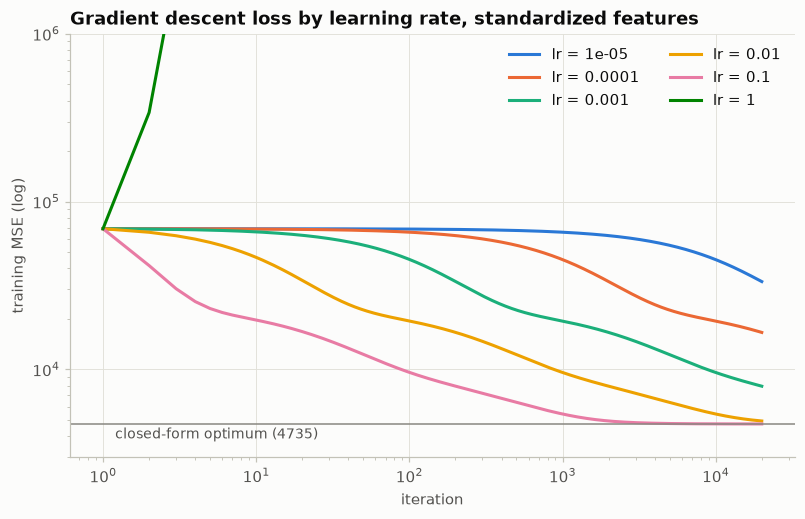

,iterations run,final MSE,final MSE / optimum
lr = 1e-05,20000,3.339228e+04,7.053000e+00
lr = 0.0001,20000,1.662071e+04,3.511000e+00
lr = 0.001,20000,7.951459e+03,1.679000e+00
lr = 0.01,20000,4.933725e+03,1.042000e+00
lr = 0.1,20000,4.737386e+03,1.001000e+00
lr = 1,10,4.441118e+12,9.380266e+08


In [16]:
PLOT_LRS = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0]
PLOT_ITERS = 20_000
X_std, mse_opt = versions["standardized"]["X"], versions["standardized"]["mse_opt"]
curves = {lr: gradient_descent(X_std, y_train, lr, PLOT_ITERS)[1] for lr in PLOT_LRS}

fig, ax = plt.subplots(figsize=(8.5, 5))
for lr, losses in curves.items():
    ax.plot(np.arange(1, len(losses) + 1), losses, label=f"lr = {lr:g}")
ax.axhline(mse_opt, color=MUTED, linewidth=1)
ax.text(1.2, mse_opt * 0.82, f"closed-form optimum ({mse_opt:.0f})", color=INK2, fontsize=9)
ax.set(xscale="log", yscale="log", ylim=(3e3, 1e6), xlabel="iteration", ylabel="training MSE (log)",
       title="Gradient descent loss by learning rate, standardized features")
ax.legend(loc="upper right", ncols=2)
fig.savefig(FIG / "gd_loss_vs_lr.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"iterations run": [len(l) for l in curves.values()],
              "final MSE": [l[-1] for l in curves.values()],
              "final MSE / optimum": [l[-1] / mse_opt for l in curves.values()]},
             index=[f"lr = {lr:g}" for lr in PLOT_LRS]).round(3)

**The two extremes**

- **lr = 1e-5 (too small):** the loss is essentially flat for the first ~1,000 iterations and, after all 20,000, is still 33,392, 7.1× the optimum. The steps are so small that only the steepest direction (mostly the overall mean level) has started to fit. lr = 1e-4 and 1e-3 show the same curve shifted left, and end at 3.5× and 1.7× the optimum.
- **lr = 1.0 (too large):** above the stability bound of 0.526. Every step overshoots along the steepest direction by more than it corrects, so the error grows geometrically: MSE goes from 69,000 to over 1e12 in 10 iterations, when the run is stopped (off the top of the plot).
- **In between:** lr = 0.1 is the largest grid value that is stable and gets within 0.1% of the optimum in 20,000 iterations. lr = 1e-2 follows the same path about 10× more slowly and ends 4.2% above it. On log–log axes, each 10× decrease in learning rate shifts the curve 10× to the right.

### 1.2.3 Visualization

All plots use the training set only, so nothing is learned from validation or test rows.

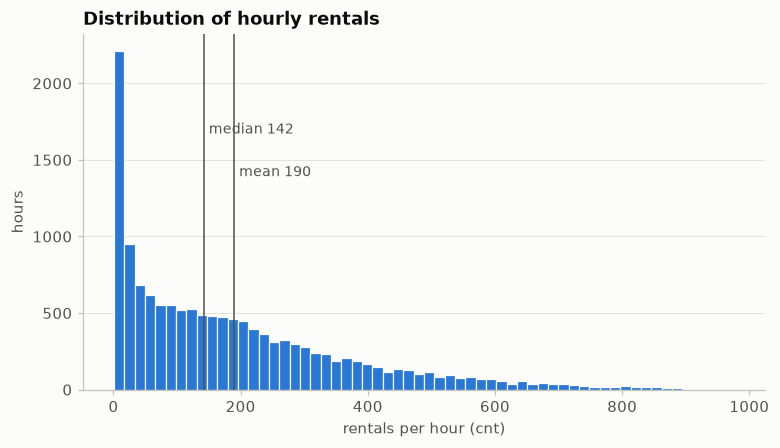

{'count': 13903.0, 'mean': 189.7, 'std': 181.6, 'min': 1.0, '25%': 40.0, '50%': 142.0, '75%': 281.0, 'max': 976.0} skew: 1.27


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(train["cnt"], bins=60, color=SERIES[0], edgecolor=SURFACE, linewidth=0.8)
for value, label, height in [(train["cnt"].median(), "median", 0.72), (train["cnt"].mean(), "mean", 0.6)]:
    ax.axvline(value, color=INK2, linewidth=1)
    ax.text(value + 8, ax.get_ylim()[1] * height, f"{label} {value:.0f}", color=INK2, fontsize=9)
ax.set(xlabel="rentals per hour (cnt)", ylabel="hours", title="Distribution of hourly rentals")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "cnt_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(train["cnt"].describe().round(1).to_dict(), "skew:", round(train["cnt"].skew(), 2))

**Target distribution:** `cnt` is strongly right-skewed (skew 1.27, median 142 < mean 190, max 976), with 2,333 of 13,903 hours (17%) below 20 rentals. Squared error will be dominated by the busy hours, and a linear model fit to raw counts is likely to predict negative values for the many near-empty night hours.

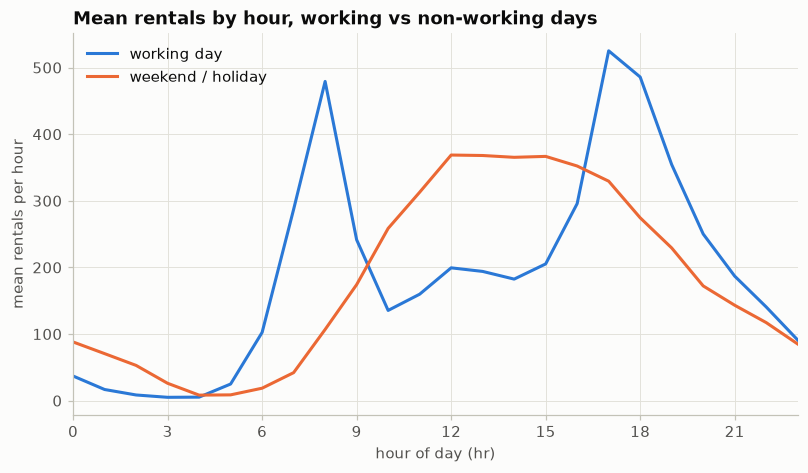

In [18]:
profile = train.pivot_table(index="hr", columns="workingday", values="cnt")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for wd, label, color in [(1, "working day", SERIES[0]), (0, "weekend / holiday", SERIES[1])]:
    ax.plot(profile.index, profile[wd], color=color, label=label)
ax.set(xlabel="hour of day (hr)", ylabel="mean rentals per hour", xticks=range(0, 24, 3), xlim=(0, 23),
       title="Mean rentals by hour, working vs non-working days")
ax.legend(loc="upper left")
fig.savefig(FIG / "cnt_by_hour_workingday.png", dpi=150, bbox_inches="tight")
plt.show()

**Hour × working day:** working days have sharp commute peaks at 08:00 (~480) and 17:00 (~525) with a midday dip, while weekends and holidays have a single broad midday plateau (~370). The hour effect is far from linear and changes shape with day type, which is exactly what one-hot `hr` and the workingday × hr interaction are there to capture.

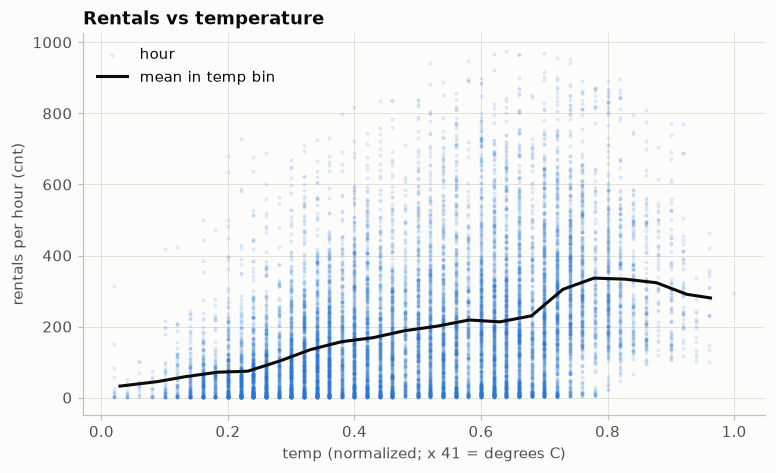

corr(temp, cnt) = 0.402


In [19]:
bins = pd.cut(train["temp"], np.linspace(0, 1, 21))
binned = train.groupby(bins, observed=True).agg(temp=("temp", "mean"), cnt=("cnt", "mean"))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(train["temp"], train["cnt"], s=6, color=SERIES[0], alpha=0.15, linewidths=0, label="hour")
ax.plot(binned["temp"], binned["cnt"], color=INK, linewidth=2, label="mean in temp bin")
ax.set(xlabel="temp (normalized; x 41 = degrees C)", ylabel="rentals per hour (cnt)",
       title="Rentals vs temperature")
ax.legend(loc="upper left")
fig.savefig(FIG / "cnt_vs_temp.png", dpi=150, bbox_inches="tight")
plt.show()
print("corr(temp, cnt) =", round(train[["temp", "cnt"]].corr().iloc[0, 1], 3))

**Temperature:** demand rises with temperature (correlation 0.40), but not linearly. The binned mean climbs from ~30 to ~335 up to temp ≈ 0.8 (~33 °C) and then falls, and the spread widens as it gets warmer. A single linear temp term can only capture part of this, which is the nonlinearity 1.4 studies directly.

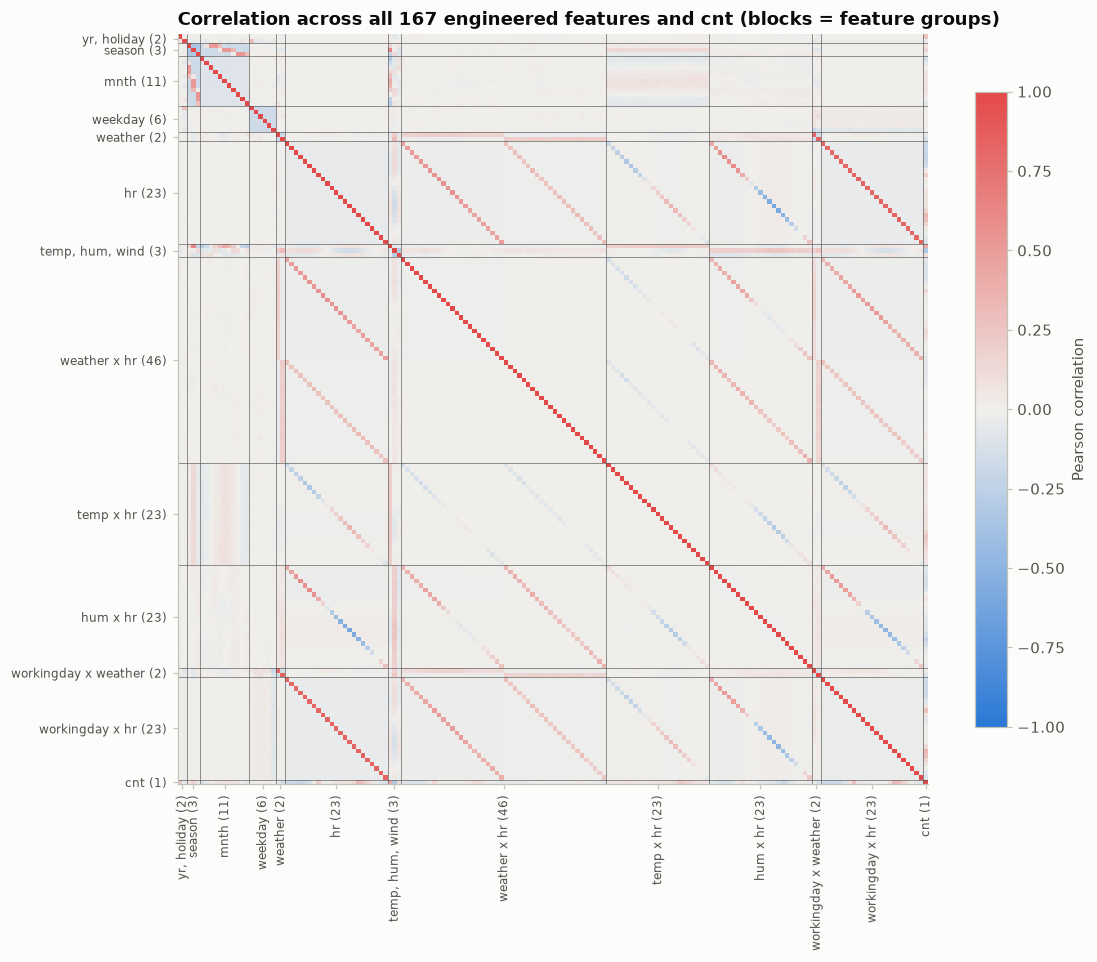

Strongest correlations with cnt:
temp                0.402
workingday*hr=17    0.321
hum                -0.319
hr=17               0.319
workingday*hr=18    0.282
workingday*hr=8     0.273
hr=18               0.266
yr                  0.249
temp*hr=17          0.236
hum*hr=17          -0.215

Strongest feature-feature correlations:
weather=3  workingday*weather=3    0.845
hr=23      workingday*hr=23        0.827
hr=18      workingday*hr=18        0.825
hr=9       workingday*hr=9         0.825
hr=14      workingday*hr=14        0.825
hr=21      workingday*hr=21        0.824
hr=11      workingday*hr=11        0.824
hr=10      workingday*hr=10        0.823
hr=17      workingday*hr=17        0.823
hr=20      workingday*hr=20        0.822


In [20]:
def feature_group(name):
    if "*" in name:
        left, right = name.split("*")
        return f"{left.split('=')[0]} x {right.split('=')[0]}"
    if name in CONTINUOUS:
        return "temp, hum, wind"
    if name in ("yr", "holiday"):
        return "yr, holiday"
    return name.split("=")[0]


F_train = build_features(train)
names = list(F_train.columns) + ["cnt"]
corr = np.corrcoef(np.column_stack([F_train.to_numpy(), y_train]), rowvar=False)
groups = [feature_group(n) for n in names]
starts = [i for i in range(len(names)) if i == 0 or groups[i] != groups[i - 1]]
ends = starts[1:] + [len(names)]

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1, interpolation="nearest")
ax.grid(False)
for s in starts[1:]:
    ax.axhline(s - 0.5, color=INK2, linewidth=0.4)
    ax.axvline(s - 0.5, color=INK2, linewidth=0.4)
centers = [(s + e - 1) / 2 for s, e in zip(starts, ends)]
ax.set_xticks(centers, [f"{groups[s]} ({e - s})" for s, e in zip(starts, ends)], rotation=90, fontsize=8)
ax.set_yticks(centers, [f"{groups[s]} ({e - s})" for s, e in zip(starts, ends)], fontsize=8)
ax.set_title(f"Correlation across all {F_train.shape[1]} engineered features and cnt (blocks = feature groups)")
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson correlation")
fig.savefig(FIG / "feature_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

corr_df = pd.DataFrame(corr, index=names, columns=names)
print("Strongest correlations with cnt:")
print(corr_df["cnt"].drop("cnt").sort_values(key=np.abs, ascending=False).head(10).round(3).to_string())
upper = corr_df.drop(index="cnt", columns="cnt").where(np.triu(np.ones((len(names) - 1,) * 2, dtype=bool), k=1))
print("\nStrongest feature-feature correlations:")
print(upper.stack().sort_values(key=np.abs, ascending=False).head(10).round(3).to_string())

**Correlation heatmap:** most engineered features are nearly uncorrelated. The structure that shows up is:
- **diagonal stripes** where each interaction tracks its parent column, e.g. workingday × hr=k with hr=k (≈ 0.82) and workingday × weather=3 with weather=3 (0.85);
- **light-blue blocks** among dummies of the same variable, which are mutually exclusive;
- **month–season blocks**, since month largely determines season.

No single feature correlates with `cnt` above 0.40 (temp), so fitting the target depends on combining many columns rather than on any one strong predictor.

## 1.3 Linear Regression from Scratch

### 1.3.1 Closed-form solution

Minimizing $L(w) = \lVert Xw - y \rVert^2$ and setting $\nabla L = 2X^T(Xw - y) = 0$ gives the normal equation
$$X^TX\,w^* = X^Ty \quad\Rightarrow\quad w^* = (X^TX)^{-1}X^Ty.$$
`fit_closed_form` (defined in 1.1 and used throughout) solves this $p \times p$ linear system directly with `np.linalg.solve` (LU factorization of $X^TX$). `fit_closed_form_inverse` forms $(X^TX)^{-1}$ explicitly and is kept only for comparison below. Continuous features are standardized as in 1.2.2.

**Condition numbers before solving** (ratio of largest to smallest singular value):

In [21]:
def fit_closed_form_inverse(X, y):
    return np.linalg.inv(X.T @ X) @ (X.T @ y)


X_train, feature_names = design(train)
cond_X, cond_XtX = np.linalg.cond(X_train), np.linalg.cond(X_train.T @ X_train)
print(f"X: {X_train.shape[0]} x {X_train.shape[1]}")
print(f"cond(X)     = {cond_X:.1f}")
print(f"cond(X^T X) = {cond_XtX:.4g}   (cond(X)^2 = {cond_X ** 2:.4g})")

w_closed = fit_closed_form(X_train, y_train)
print(f"\nClosed-form training RMSE = {rmse(y_train, X_train @ w_closed):.2f}")

X: 13903 x 168
cond(X)     = 138.8
cond(X^T X) = 1.926e+04   (cond(X)^2 = 1.926e+04)

Closed-form training RMSE = 68.81


**Result:** cond(X) = 138.8 and cond(XᵀX) = 1.93e4, with **training RMSE 68.81**. As expected, forming $X^TX$ squares the condition number. This is moderate, not "very large": in double precision it costs at most about 4–5 of the ~16 significant digits. The design matrix is well-conditioned because 1.1 already avoided redundant representations:
- one-hot encodings drop a baseline level;
- `workingday` is not included as a main effect;
- `atemp` is excluded.

What remains comes from rare 0/1 columns. The smallest singular direction is almost entirely the rain × midday-hour interaction columns, which are non-zero in only a few dozen training rows each.

**Diagnosing what a redundant representation does.** To show where ill-conditioning would come from, the same matrix is rebuilt the naive way. It keeps **every** one-hot level (adding back season=1, mnth=1, weekday=0, weather=1 and hr=0) and adds `workingday` as a main effect.

In [22]:
def redundant_design(d):
    """Final design plus the dropped baseline dummies and the workingday main effect."""
    F = build_features(d)
    extra = pd.DataFrame({"season=1": d["season"] == 1, "mnth=1": d["mnth"] == 1, "weekday=0": d["weekday"] == 0,
                          "weather=1": d["weathersit"] == 1, "hr=0": d["hr"] == 0,
                          "workingday": d["workingday"] == 1}, index=d.index).astype(float)
    F = pd.concat([F, extra], axis=1)
    return np.column_stack([np.ones(len(F)), F.to_numpy()]), ["intercept"] + list(F.columns)


X_red, names_red = redundant_design(train)
sv_red = np.linalg.svd(X_red, compute_uv=False)
print(f"redundant X: {X_red.shape[0]} x {X_red.shape[1]}, numerical rank {np.linalg.matrix_rank(X_red)}")
print(f"cond(X)     = {np.linalg.cond(X_red):.3g}")
print(f"cond(X^T X) = {np.linalg.cond(X_red.T @ X_red):.3g}")
print("8 smallest singular values:", np.array2string(sv_red[-8:], precision=2))

R = pd.DataFrame(X_red, columns=names_red)
group_sum = lambda pattern: R.filter(regex=pattern).sum(axis=1)
exact_dependencies = {
    "season=1..4 sum to intercept": group_sum(r"^season=\d+$") - R["intercept"],
    "mnth=1..12 sum to intercept": group_sum(r"^mnth=\d+$") - R["intercept"],
    "weekday=0..6 sum to intercept": group_sum(r"^weekday=\d+$") - R["intercept"],
    "weather=1..3 sum to intercept": group_sum(r"^weather=\d+$") - R["intercept"],
    "hr=0..23 sum to intercept": group_sum(r"^hr=\d+$") - R["intercept"],
    "workingday = weekday 1..5 - holiday": R["workingday"] - (R[[f"weekday={k}" for k in range(1, 6)]].sum(axis=1) - R["holiday"]),
}
print("\nmax |residual| of each suspected linear dependency:")
for name, residual in exact_dependencies.items():
    print(f"  {name:38s} {residual.abs().max():.1f}")

for label, fit in [("np.linalg.solve", fit_closed_form), ("explicit inverse", fit_closed_form_inverse)]:
    w = fit(X_red, y_train)
    print(f"\n{label}: training RMSE = {rmse(y_train, X_red @ w):,.2f}, largest |weight| = {np.abs(w).max():,.1f}")

redundant X: 13903 x 174, numerical rank 168


cond(X)     = 2.02e+16
cond(X^T X) = 2.01e+17
8 smallest singular values: [2.08e+00 1.18e+00 6.85e-14 3.15e-14 2.64e-14 1.99e-14 1.62e-14 9.94e-15]

max |residual| of each suspected linear dependency:
  season=1..4 sum to intercept           0.0
  mnth=1..12 sum to intercept            0.0
  weekday=0..6 sum to intercept          0.0
  weather=1..3 sum to intercept          0.0
  hr=0..23 sum to intercept              0.0
  workingday = weekday 1..5 - holiday    0.0



np.linalg.solve: training RMSE = 68.81, largest |weight| = 489.4

explicit inverse: training RMSE = 24,279.29, largest |weight| = 29,530.0


**Diagnosis.** The redundant matrix has 174 columns but numerical rank 168. It has exactly **six** singular values at round-off level (~1e-14), matching six exact linear dependencies, each verified above with residual 0:
- **the dummy-variable trap, five times:** all levels of season, month, weekday, weather and hour each sum to the intercept column;
- **workingday** equals (weekday 1–5) − holiday.

$X^TX$ is therefore singular. Its condition number, 2.0e16 for X and 2.0e17 for XᵀX, is simply the largest value double precision can represent, not a meaningful measurement. The normal equation no longer has a unique solution: any multiple of the null-space directions can be added to $w$ without changing predictions. `np.linalg.solve` happens to return one of the infinitely many minimizers (RMSE 68.81, but arbitrary weights). The explicit inverse amplifies round-off error by ~1e17 and produces nonsense (training RMSE ≈ 24,279).

**Correction.** Drop one baseline level from each one-hot group (the intercept absorbs it) and drop the `workingday` main effect (it is still available inside its interactions). That is exactly the 1.1 representation. For completeness, adding back the near-redundant `atemp` (corr 0.988 with temp) would raise the condition numbers only slightly, because that redundancy is approximate rather than exact.

In [23]:
X_atemp = np.column_stack([X_train, ((train["atemp"] - train["atemp"].mean()) / train["atemp"].std()).to_numpy()])
pd.DataFrame({
    "columns": [X_red.shape[1], X_train.shape[1], X_atemp.shape[1]],
    "rank": [np.linalg.matrix_rank(M) for M in (X_red, X_train, X_atemp)],
    "cond(X)": [np.linalg.cond(M) for M in (X_red, X_train, X_atemp)],
    "cond(X^T X)": [np.linalg.cond(M.T @ M) for M in (X_red, X_train, X_atemp)],
}, index=["redundant (all levels + workingday)", "corrected (final, 1.1)", "corrected + atemp"]).style.format(
    {"cond(X)": "{:.3g}", "cond(X^T X)": "{:.3g}"})

,columns,rank,cond(X),cond(X^T X)
redundant (all levels + workingday),174,168,2.02e+16,2.01e+17
"corrected (final, 1.1)",168,168,139,1.93e+04
corrected + atemp,169,169,150,2.24e+04


### 1.3.2 Gradient descent

`gradient_descent` from 1.2.2 (full-batch, MSE loss, starting from $w = 0$) is run on the same standardized design matrix at **lr = 0.5**, the largest stable learning rate found in 1.2.2. The weights are compared with the closed-form solution after increasing numbers of iterations.

In [24]:
GD_LR = 0.5
comparison = {}
for n_iters in [1_000, 10_000, 50_000, 100_000, 200_000, 300_000]:
    w_gd, _ = gradient_descent(X_train, y_train, GD_LR, n_iters)
    comparison[n_iters] = {
        "max |w_gd - w_closed|": np.abs(w_gd - w_closed).max(),
        "relative L2 difference": np.linalg.norm(w_gd - w_closed) / np.linalg.norm(w_closed),
        "train RMSE (GD)": rmse(y_train, X_train @ w_gd),
        "RMSE between predictions": rmse(X_train @ w_gd, X_train @ w_closed),
    }
comparison = pd.DataFrame(comparison).T.rename_axis("iterations")
comparison.style.format("{:.3g}").format({"train RMSE (GD)": "{:.4f}"})

,max |w_gd - w_closed|,relative L2 difference,train RMSE (GD),RMSE between predictions
iterations,,,,
1000,56.020222,0.235180,69.0289,5.519155
10000,18.051580,0.078268,68.8139,0.902138
50000,0.350020,0.001504,68.8079,0.017314
100000,0.002507,0.000011,68.8079,0.000124
200000,0.000000,0.000000,68.8079,0.000000
300000,0.000000,0.000000,68.8079,0.000000


In [25]:
top = np.argsort(-np.abs(w_closed))[:10]
pd.DataFrame({"closed form": w_closed[top], f"GD ({n_iters:,} iters)": w_gd[top], "difference": w_gd[top] - w_closed[top]},
             index=[feature_names[i] for i in top]).style.format({"closed form": "{:.6f}", f"GD ({n_iters:,} iters)": "{:.6f}", "difference": "{:.2e}"})

,closed form,"GD (300,000 iters)",difference
workingday*hr=8,428.714305,428.714305,-9.66e-12
workingday*hr=7,305.757830,305.757830,-9.72e-12
hr=12,272.898154,272.898154,-1.01e-11
hr=13,261.488783,261.488783,-9.95e-12
hr=14,260.558199,260.558199,-1.04e-11
workingday*hr=18,258.576976,258.576976,-8.87e-12
hr=15,257.854017,257.854017,-1.03e-11
workingday*hr=17,250.234924,250.234924,-7.33e-12
hr=16,241.767085,241.767085,-8.81e-12
hr=11,227.047448,227.047448,-7.56e-12


**Correctness check: passed.** After 300,000 iterations the gradient descent weights match the closed-form solution to a largest elementwise difference of **5.5e-11** (relative L2 difference 2.3e-13). That is round-off level; running longer does not reduce it further. Both methods therefore find the same minimizer, and the training RMSE of 68.81 agrees.

**Why so many iterations, when the loss converged much earlier?** In 1.2.2 the loss was within 0.1% of the optimum after only 4,355 iterations (even at the smaller lr = 0.3). Yet here, at 10,000 iterations, the training RMSE already reads 68.81 while individual weights still differ by up to 18. The error along each eigenvector of $X^TX/n$ shrinks by a factor $(1 - 2\eta\lambda)$ per iteration. For the smallest eigenvalue ($\lambda_{min} = 9.9 \times 10^{-5}$, the rare rain × hour columns) at $\eta = 0.5$ that factor is $1 - 9.9 \times 10^{-5}$: one factor-of-$e$ reduction takes about 10,000 iterations. This matches the table: the difference falls by $e^{9.9} \approx 2 \times 10^4$ between 100k and 200k iterations. Those directions barely affect the loss (few rows are non-zero there), so the loss settles long before those weights do. Checking agreement of weights rather than loss is the stricter test.

## 1.4 Polynomial Features and the Bias-Variance Tradeoff

Dataset: `bike_temp_comfort_zone.csv` (800 rows: `temp`, `demand`, `split`), using its own `split` column: 400 train, 200 validation, 200 test. For each degree $d = 1, \dots, 12$ the features are $temp, temp^2, \dots, temp^d$. Each power is standardized with the mean and standard deviation of that power on the training set, then an intercept is added and the model is fit with the closed-form normal equation (`fit_closed_form`).

In [26]:
comfort = pd.read_csv("data/bike_temp_comfort_zone.csv")
ct = {s: comfort[comfort["split"] == s] for s in ["train", "val", "test"]}
print({s: len(part) for s, part in ct.items()})

DEGREES = range(1, 13)


def poly_design(t, degree, mean, std):
    P = np.column_stack([t ** k for k in range(1, degree + 1)])
    return np.column_stack([np.ones(len(t)), (P - mean) / std])


poly_fits, poly_rows = {}, {}
for degree in DEGREES:
    P_train = np.column_stack([ct["train"]["temp"].to_numpy() ** k for k in range(1, degree + 1)])
    mean, std = P_train.mean(axis=0), P_train.std(axis=0)
    X = {s: poly_design(ct[s]["temp"].to_numpy(), degree, mean, std) for s in ct}
    y = {s: ct[s]["demand"].to_numpy() for s in ct}
    w = fit_closed_form(X["train"], y["train"])
    w_lstsq = np.linalg.lstsq(X["train"], y["train"], rcond=None)[0]
    poly_fits[degree] = {"w": w, "X": X, "y": y}
    poly_rows[degree] = {
        "train RMSE": rmse(y["train"], X["train"] @ w),
        "val RMSE": rmse(y["val"], X["val"] @ w),
        "max |coef| (no intercept)": np.abs(w[1:]).max(),
        "cond(X^T X)": np.linalg.cond(X["train"].T @ X["train"]),
        "train RMSE (lstsq check)": rmse(y["train"], X["train"] @ w_lstsq),
    }
poly_results = pd.DataFrame(poly_rows).T.rename_axis("degree")
poly_results.style.format({"train RMSE": "{:.3f}", "val RMSE": "{:.3f}", "max |coef| (no intercept)": "{:.3g}",
                           "cond(X^T X)": "{:.2g}", "train RMSE (lstsq check)": "{:.3f}"})

{'train': 400, 'val': 200, 'test': 200}


,train RMSE,val RMSE,max |coef| (no intercept),cond(X^T X),train RMSE (lstsq check)
degree,,,,,
1,117.287,121.770,73.3,1,117.287
2,79.083,74.988,404,60,79.083
3,63.348,60.557,701,2.3e+03,63.348
4,60.978,57.773,2.69e+03,9.2e+04,60.978
5,60.297,56.720,4.02e+03,3.2e+06,60.297
6,60.292,56.714,1.88e+03,1e+08,60.292
7,60.290,56.691,7.35e+03,3.6e+09,60.290
8,60.235,57.172,2.16e+05,1.2e+11,60.235
9,60.133,57.527,1.74e+06,4.2e+12,60.133


lowest validation RMSE: degree 7 (56.691)
degrees within 0.1% of it: [5, 6, 7]


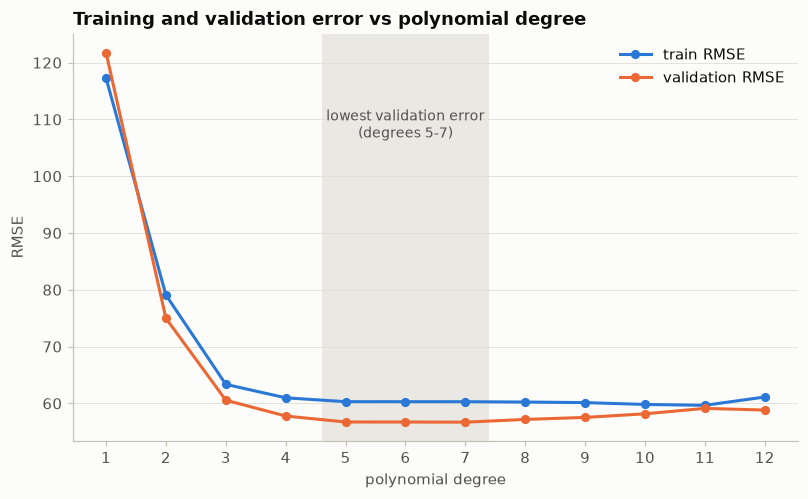

In [27]:
best_degree = int(poly_results["val RMSE"].idxmin())
best_val = poly_results.loc[best_degree, "val RMSE"]
region = [d for d in DEGREES if poly_results.loc[d, "val RMSE"] <= best_val * 1.001]
print(f"lowest validation RMSE: degree {best_degree} ({best_val:.3f})")
print(f"degrees within 0.1% of it: {region}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.axvspan(min(region) - 0.4, max(region) + 0.4, color=GRID, alpha=0.7, linewidth=0)
ax.text((min(region) + max(region)) / 2, 112, f"lowest validation error\n(degrees {min(region)}-{max(region)})",
        ha="center", va="top", color=INK2, fontsize=9)
ax.plot(list(DEGREES), poly_results["train RMSE"], marker="o", markersize=5, color=SERIES[0], label="train RMSE")
ax.plot(list(DEGREES), poly_results["val RMSE"], marker="o", markersize=5, color=SERIES[1], label="validation RMSE")
ax.set(xlabel="polynomial degree", ylabel="RMSE", xticks=list(DEGREES),
       title="Training and validation error vs polynomial degree")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.savefig(FIG / "poly_error_vs_degree.png", dpi=150, bbox_inches="tight")
plt.show()

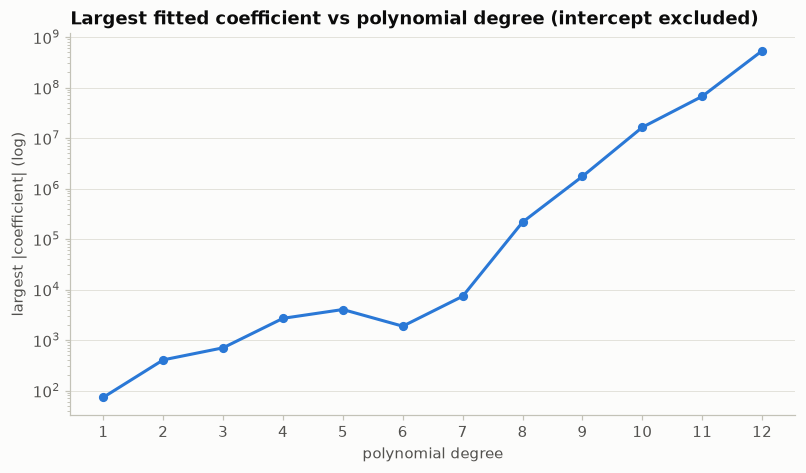

In [28]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(list(DEGREES), poly_results["max |coef| (no intercept)"], marker="o", markersize=5, color=SERIES[0])
ax.set(yscale="log", xlabel="polynomial degree", ylabel="largest |coefficient| (log)", xticks=list(DEGREES),
       title="Largest fitted coefficient vs polynomial degree (intercept excluded)")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "poly_max_coef_vs_degree.png", dpi=150, bbox_inches="tight")
plt.show()

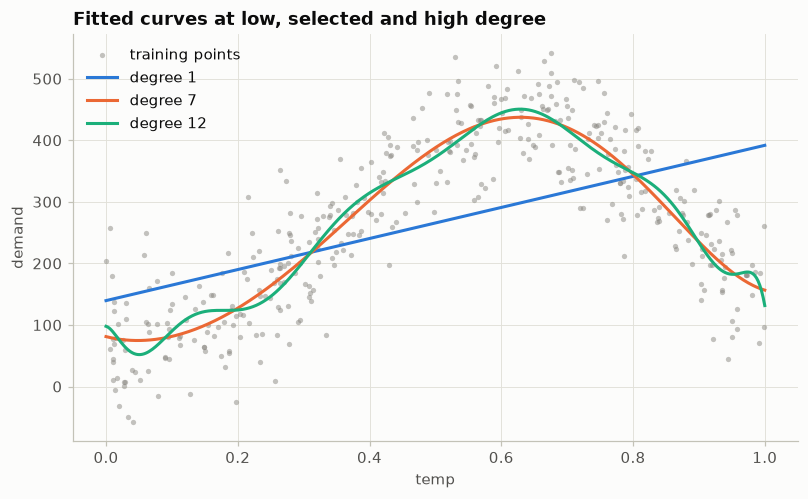

In [29]:
t_grid = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.scatter(ct["train"]["temp"], ct["train"]["demand"], s=12, color=MUTED, alpha=0.5, linewidths=0, label="training points")
for degree, color in [(1, SERIES[0]), (best_degree, SERIES[1]), (12, SERIES[2])]:
    P_train = np.column_stack([ct["train"]["temp"].to_numpy() ** k for k in range(1, degree + 1)])
    grid_X = poly_design(t_grid, degree, P_train.mean(axis=0), P_train.std(axis=0))
    ax.plot(t_grid, grid_X @ poly_fits[degree]["w"], color=color, label=f"degree {degree}")
ax.set(xlabel="temp", ylabel="demand", title="Fitted curves at low, selected and high degree")
ax.legend(loc="upper left")
fig.savefig(FIG / "poly_fits.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
fit = poly_fits[best_degree]
test_rmse_poly = rmse(fit["y"]["test"], fit["X"]["test"] @ fit["w"])
print(f"Selected degree {best_degree}: train RMSE {poly_results.loc[best_degree, 'train RMSE']:.3f}, "
      f"val RMSE {best_val:.3f}, test RMSE {test_rmse_poly:.3f}")

Selected degree 7: train RMSE 60.290, val RMSE 56.691, test RMSE 52.614


**Region where validation error is minimized: degrees 5–7.** Validation RMSE is 56.720, 56.714 and 56.691 there, all within 0.1% of each other. The neighbours are clearly worse: degree 4 is 57.773 and degree 8 is 57.172. Degree 7 has the lowest validation error, and its **test RMSE is 52.614**. The test set was evaluated only at this one degree.

**Left of the region (degrees 1–4): underfitting, high bias.** Both curves are high and fall steeply together. A line (degree 1: train 117.3, val 121.8) cannot bend at all. A parabola (degree 2) can make a hump, but only a symmetric one, while demand rises slowly from cold temperatures, peaks near temp ≈ 0.65 and falls quickly. Each extra degree lets the curve match that shape better, so training and validation error drop by similar amounts: the model is limited by its form, not by the data.

**Right of the region (degrees 8–12): overfitting, high variance.** Training error keeps creeping down (60.29 at degree 7 to 59.39 at degree 12 with `lstsq`), because each added power is free to chase noise in the 400 training points. Validation error rises instead (56.69 to about 59), so the extra flexibility fits patterns that do not generalize. The fitted degree-12 curve wiggles, especially near the edges of the temperature range where there are few points to pin it down. Validation RMSE is below training RMSE at low degrees only because this particular 200-point validation sample happens to be slightly less noisy. The trend, not the level, is what matters.

**Coefficient magnitude.** The largest coefficient grows from 73 at degree 1 to about 5e8 at degree 12. It stays in the hundreds to thousands through the selected region, then jumps about 30× between degrees 7 and 8 and keeps climbing by roughly an order of magnitude per degree after that. That is exactly where validation error starts to rise. Standardized powers of the same variable are almost collinear (e.g. $temp^{11}$ and $temp^{12}$), so the fit represents a smooth curve as huge coefficients of opposite sign that nearly cancel. That cancellation is what makes the high-degree model so sensitive to small changes in the data, which is the variance side of the tradeoff and what regularization (1.5) penalizes.

**Numerical note.** The same collinearity drives cond(XᵀX) from 1 at degree 1 to 7.8e16 at degree 12, which is beyond what double precision can resolve. At degree 12 the normal-equation fit reports a training RMSE of 61.12, higher than degree 11's 59.66. That cannot be a true least-squares result, since degree 12 contains degree 11 as a special case. It is round-off error from solving the normal equations. `np.linalg.lstsq`, which works on X directly (condition number ≈ the square root), gives 59.39. Degrees 1–11 agree between the two methods to the displayed precision, so the selected region and test RMSE are unaffected.

## 1.5 Regularization

**Ridge regression** minimizes
$$L(w) = \lVert Xw - y \rVert^2 + \lambda \sum_{j \ge 1} w_j^2,$$
where the intercept $w_0$ is not penalized, so shrinkage never pulls predictions towards 0 rather than towards the mean. Setting the gradient to zero gives
$$(X^TX + \lambda D)\,w = X^Ty, \qquad D = \mathrm{diag}(0, 1, \dots, 1),$$
solved directly with `np.linalg.solve`. At $\lambda = 0$, $X^TX$ can be singular (the 100-row case below), so that fit uses the least-squares solver `np.linalg.lstsq`, which returns the minimum-norm solution. On the full training set it coincides with the normal-equation solution.

**Preprocessing.** The penalty treats all weights alike, so every feature column (not only the continuous ones) is standardized with the mean and standard deviation of the rows being fit. Zero-variance columns of those rows are dropped first. Validation rows use the same statistics.

**Validation set.** Both sweeps are evaluated on the same 1,737-row validation set from the main split.

In [31]:
LAMBDAS = [0, 1e-2, 1, 10, 100, 1e3, 1e4, 1e5, 1e6]
LAMBDA_LABELS = ["0", "1e-2", "1", "10", "100", "1e3", "1e4", "1e5", "1e6"]
F_train_all, F_val_all = build_features(train), build_features(val)


def ridge_matrices(F_fit, F_eval):
    """Drop zero-variance columns of F_fit, standardize both frames with F_fit statistics, add an intercept."""
    keep = F_fit.columns[F_fit.std() > 0]
    mean, std = F_fit[keep].mean(), F_fit[keep].std()
    to_X = lambda F: np.column_stack([np.ones(len(F)), ((F[keep] - mean) / std).to_numpy()])
    return to_X(F_fit), to_X(F_eval), list(keep)


def fit_ridge(X, y, lam):
    """Minimize ||Xw - y||^2 + lam * ||w[1:]||^2 (intercept unpenalized)."""
    if lam == 0:
        return np.linalg.lstsq(X, y, rcond=None)[0]
    D = np.eye(X.shape[1])
    D[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam * D, X.T @ y)


def ridge_sweep(fit_rows):
    X_fit, X_val, kept = ridge_matrices(F_train_all.loc[fit_rows.index], F_val_all)
    y_fit, y_val = fit_rows["cnt"].to_numpy(float), val["cnt"].to_numpy(float)
    weights = {lam: fit_ridge(X_fit, y_fit, lam) for lam in LAMBDAS}
    results = pd.DataFrame({lam: {"train RMSE": rmse(y_fit, X_fit @ w), "val RMSE": rmse(y_val, X_val @ w)}
                            for lam, w in weights.items()}).T.rename_axis("lambda")
    return results, weights, kept


def improvement(results):
    best = results["val RMSE"].idxmin()
    base, best_val = results.loc[0, "val RMSE"], results.loc[best, "val RMSE"]
    return best, base, best_val, base - best_val


def plot_sweep(results, title, filename, label_offset, legend_loc="upper left"):
    pos = np.arange(len(LAMBDAS))
    best = LAMBDAS.index(results["val RMSE"].idxmin())
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.plot(pos, results["train RMSE"], marker="o", markersize=5, color=SERIES[0], label="train RMSE")
    ax.plot(pos, results["val RMSE"], marker="o", markersize=5, color=SERIES[1], label="validation RMSE")
    ax.annotate(f"best lambda = {LAMBDA_LABELS[best]}\nval RMSE {results['val RMSE'].iloc[best]:.2f}",
                (pos[best], results["val RMSE"].iloc[best]), xytext=label_offset, textcoords="offset points",
                ha="center", color=INK2, fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8})
    ax.set_xticks(pos, LAMBDA_LABELS)
    ax.set(xlabel="regularization strength lambda (0, then log-spaced)", ylabel="RMSE", title=title)
    ax.grid(axis="x", visible=False)
    ax.legend(loc=legend_loc)
    fig.savefig(FIG / filename, dpi=150, bbox_inches="tight")
    plt.show()

### Sweep on the full training set

rows: 13903, columns incl. intercept: 168, zero-variance columns dropped: 0
lambda = 0: val RMSE 68.560 | best lambda = 100: val RMSE 68.530 | improvement 0.031 (0.04%)


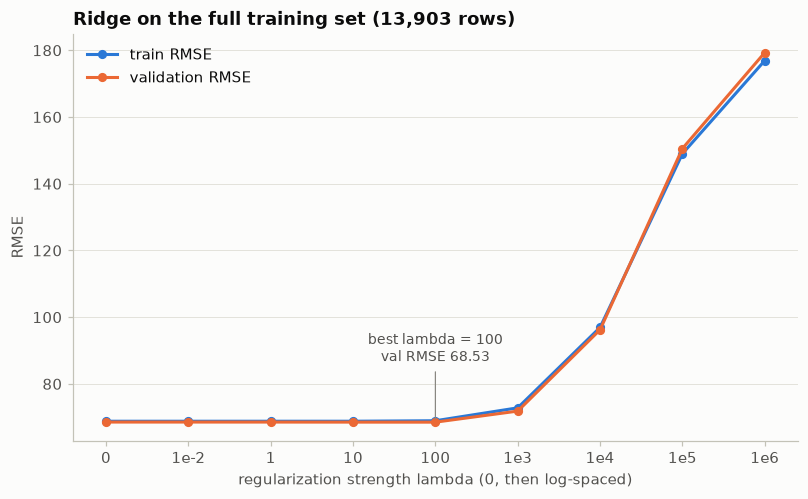

,train RMSE,val RMSE
lambda,,
0.000000,68.808,68.560
0.010000,68.808,68.560
1.000000,68.808,68.558
10.000000,68.810,68.541
100.000000,68.954,68.530
1000.000000,72.825,71.848
10000.000000,96.931,96.239
100000.000000,149.000,150.547
1000000.000000,176.911,179.315


In [32]:
full_sweep, full_weights, full_kept = ridge_sweep(train)
ridge_lambda = improvement(full_sweep)[0]
print(f"rows: {len(train)}, columns incl. intercept: {len(full_kept) + 1}, zero-variance columns dropped: {F_train_all.shape[1] - len(full_kept)}")
best, base, best_val, gain = improvement(full_sweep)
print(f"lambda = 0: val RMSE {base:.3f} | best lambda = {best:g}: val RMSE {best_val:.3f} | "
      f"improvement {gain:.3f} ({100 * gain / base:.2f}%)")
plot_sweep(full_sweep, "Ridge on the full training set (13,903 rows)", "ridge_full.png", (0, 40))
full_sweep.style.format("{:.3f}")

**Full training set:** the best value is **λ = 100**, with validation RMSE **68.530** against **68.560** at λ = 0. That is an improvement of **0.031 RMSE (0.04%)**, which is effectively none and well within what a different validation sample would change. Up to λ = 100 both curves are flat. From λ = 1e3 onwards the penalty starts removing real signal, so training and validation error rise together. By λ = 1e6 the model is close to predicting the training mean (RMSE ≈ 177–179, about the standard deviation of `cnt`).

### Sweep on a random 100-row subsample of the training set

rows: 100, columns incl. intercept: 140, zero-variance columns dropped: 28
dropped (first 10): ['hr=10', 'weather=2*hr=2', 'weather=2*hr=10', 'weather=2*hr=18', 'weather=2*hr=19', 'weather=2*hr=21', 'weather=2*hr=22', 'weather=3*hr=2', 'weather=3*hr=4', 'weather=3*hr=5']
lambda = 0: val RMSE 324.26 | best lambda = 10: val RMSE 130.16 | improvement 194.10 (59.9%)


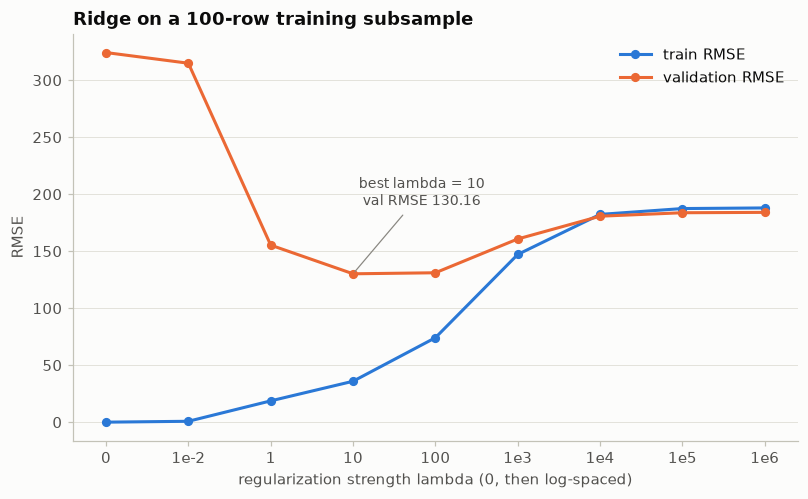

,train RMSE,val RMSE
lambda,,
0.000000,0.00,324.26
0.010000,0.77,314.90
1.000000,18.68,155.31
10.000000,35.88,130.16
100.000000,74.09,131.06
1000.000000,147.13,160.72
10000.000000,182.28,180.69
100000.000000,187.41,183.73
1000000.000000,187.94,184.05


In [33]:
subsample = train.sample(100, random_state=SEED)
sub_sweep, sub_weights, sub_kept = ridge_sweep(subsample)
F_sub = F_train_all.loc[subsample.index]
dropped = [c for c in F_sub.columns if c not in sub_kept]
print(f"rows: {len(subsample)}, columns incl. intercept: {len(sub_kept) + 1}, zero-variance columns dropped: {len(dropped)}")
print("dropped (first 10):", dropped[:10])
best, base, best_val, gain = improvement(sub_sweep)
print(f"lambda = 0: val RMSE {base:.2f} | best lambda = {best:g}: val RMSE {best_val:.2f} | "
      f"improvement {gain:.2f} ({100 * gain / base:.1f}%)")
plot_sweep(sub_sweep, "Ridge on a 100-row training subsample", "ridge_subsample.png", (45, 45), legend_loc="upper right")
sub_sweep.style.format("{:.2f}")

**100-row subsample (seed 42):** 28 engineered columns are constant in these 100 rows, mostly rare interaction cells that never occur in them, and are dropped. That leaves 139 features plus an intercept for only 100 rows. At λ = 0 the model has more parameters than data points, so it **interpolates the training set (train RMSE 0.00)** and validation RMSE is **324.26**. The best value is **λ = 10**, with validation RMSE **130.16**: an improvement of **194.10 RMSE (59.9%)**. Training error rises steadily with λ while validation error first falls sharply, then rises again past λ = 100 as the model underfits.

The result does not depend on the particular subsample. Repeating it for 20 other random subsamples:

In [34]:
rows = []
for seed in range(20):
    res, _, kept = ridge_sweep(train.sample(100, random_state=seed))
    best, base, best_val, gain = improvement(res)
    rows.append({"seed": seed, "columns kept": len(kept) + 1, "best lambda": best,
                 "val RMSE (lambda = 0)": base, "val RMSE (best lambda)": best_val, "improvement": gain})
robust = pd.DataFrame(rows).set_index("seed")
print("best lambda counts:", robust["best lambda"].value_counts().to_dict())
print(f"improvement: median {robust['improvement'].median():.1f}, min {robust['improvement'].min():.1f}, "
      f"max {robust['improvement'].max():.1f}")
robust.style.format({"best lambda": "{:g}", "val RMSE (lambda = 0)": "{:.1f}", "val RMSE (best lambda)": "{:.1f}", "improvement": "{:.1f}"})

best lambda counts: {100.0: 16, 10.0: 3, 100000.0: 1}
improvement: median 120.1, min 29.5, max 915.7


,columns kept,best lambda,val RMSE (lambda = 0),val RMSE (best lambda),improvement
seed,,,,,
0,140,100,217.6,130.8,86.8
1,147,100000,687.2,184.0,503.2
2,147,100,179.6,132.1,47.6
3,135,100,285.1,135.4,149.7
4,144,10,177.2,129.0,48.1
5,141,100,199.4,132.2,67.2
6,139,10,894.9,118.2,776.8
7,144,100,202.1,120.1,82.0
8,145,100,289.9,141.4,148.5


Across the 20 subsamples, the best λ is 10 or 100 in 19 cases, and regularization always helps substantially. The median improvement is about 120 RMSE, and the smallest is 29.5. How badly λ = 0 does varies a lot (validation RMSE 166 to 1,038), because an interpolating fit depends heavily on which 100 rows it happened to see.

### Why the two improvements differ

Ridge trades a little **bias** (weights pulled towards 0) for less **variance** (weights that change less from one training sample to another). It only helps when variance is the bigger problem.

- **Full training set: essentially no variance to remove.** With 13,903 rows for 168 columns (about 83 rows per parameter), every weight is estimated from plenty of data, and cond(X) is only 139 (1.3.1). The unregularized solution barely changes between training samples, so it is already close to the best linear fit. Shrinking adds bias without a matching variance reduction, which is why the gain is 0.03 and large λ only hurts.
- **100-row subsample: variance dominates.** With 139 features and 100 rows, $X^TX$ is singular (rank ≤ 100), so infinitely many weight vectors fit the training data exactly. The minimum-norm one fits the noise in those particular rows and swings wildly on new rows. Ridge makes $X^TX + \lambda D$ invertible and shrinks the poorly determined directions hardest: along an eigenvector of $X^TX$ with eigenvalue $d_j$, the unregularized component is scaled by $d_j/(d_j + \lambda)$. Directions the data pins down (large $d_j$) are kept, and directions it barely sees ($d_j$ near 0) are suppressed. That removes a large amount of variance for a small increase in bias.
- **The same λ is also much stronger on less data.** The data term $\lVert Xw - y \rVert^2$ is a sum over rows and grows with $n$, while the penalty does not. λ = 100 is small next to 13,903 rows of squared error, but a strong pull when there are only 100 rows.

Even the best 100-row model (validation RMSE 130) is far worse than the full-data model (68.5): regularization can control variance, but it cannot replace data.

## 1.6 Evaluation

The model is the ridge regression from 1.5, fit on the full training set at the regularization strength selected by the full-training-set sweep (**λ = 100**), with the same column standardization (training-set statistics). It is applied once to the 1,739-row test set. Metrics are implemented from scratch:

- **MAE** $= \frac{1}{n}\sum_i |y_i - \hat y_i|$
- **RMSE** $= \sqrt{\frac{1}{n}\sum_i (y_i - \hat y_i)^2}$
- **R²** $= 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$
- **Pearson r** $= \frac{\sum_i (y_i - \bar y)(\hat y_i - \bar{\hat y})}{\sqrt{\sum_i (y_i - \bar y)^2 \, \sum_i (\hat y_i - \bar{\hat y})^2}}$

Predictions are **not clipped**.

In [35]:
def mae(y, y_hat):
    return float(np.mean(np.abs(y - y_hat)))


def r2(y, y_hat):
    return float(1 - np.sum((y - y_hat) ** 2) / np.sum((y - np.mean(y)) ** 2))


def pearson(y, y_hat):
    a, b = y - y.mean(), y_hat - y_hat.mean()
    return float(a @ b / np.sqrt((a @ a) * (b @ b)))


def regression_metrics(y, y_hat):
    return {"MAE": mae(y, y_hat), "RMSE": rmse(y, y_hat), "R^2": r2(y, y_hat), "Pearson r": pearson(y, y_hat)}


F_test_all = build_features(test)
_, X_test_ridge, _ = ridge_matrices(F_train_all, F_test_all)
w_ridge = full_weights[ridge_lambda]
y_test = test["cnt"].to_numpy(float)
pred_test = X_test_ridge @ w_ridge

print(f"Ridge regression, lambda = {ridge_lambda:g}, fit on {len(train)} training rows, evaluated on {len(test)} test rows")
test_metrics = pd.DataFrame({"Ridge (lambda = 100), test set": regression_metrics(y_test, pred_test)}).T
test_metrics.style.format("{:.3f}")

Ridge regression, lambda = 100, fit on 13903 training rows, evaluated on 1739 test rows


,MAE,RMSE,R^2,Pearson r
"Ridge (lambda = 100), test set",49.023,67.030,0.857,0.926


In [36]:
neg = pred_test < 0
print(f"negative predictions: {neg.sum()} of {len(pred_test)} test rows ({100 * neg.mean():.1f}%), "
      f"most negative {pred_test.min():.1f}")
print(f"actual cnt in those rows: median {np.median(y_test[neg]):.0f}, max {y_test[neg].max():.0f}")
print("hour of day of negative predictions:", test.loc[neg, "hr"].value_counts().sort_index().to_dict())
print("weathersit of negative predictions:", test.loc[neg, "weathersit"].value_counts().sort_index().to_dict())

pd.DataFrame({"no clipping (reported)": regression_metrics(y_test, pred_test),
              "clipped at 0 (comparison only)": regression_metrics(y_test, np.clip(pred_test, 0, None))}).T.style.format("{:.3f}")

negative predictions: 181 of 1739 test rows (10.4%), most negative -108.6
actual cnt in those rows: median 9, max 77
hour of day of negative predictions: {0: 10, 1: 24, 2: 26, 3: 29, 4: 29, 5: 26, 6: 8, 7: 9, 8: 3, 10: 1, 11: 3, 15: 1, 19: 2, 22: 3, 23: 7}
weathersit of negative predictions: {1: 97, 2: 61, 3: 23}


,MAE,RMSE,R^2,Pearson r
no clipping (reported),49.023,67.030,0.857,0.926
clipped at 0 (comparison only),45.424,64.989,0.866,0.932


### Test-set results (ridge, λ = 100, no clipping)

| Metric | Test set |
|---|---|
| MAE | **49.02** |
| RMSE | **67.03** |
| R² | **0.857** |
| Pearson r | **0.926** |

The model explains about 86% of the variance in hourly rentals, and its predictions are strongly linearly correlated with the truth (r² = 0.926² ≈ 0.857, matching R²). Test RMSE (67.03) is in line with training (68.95) and validation (68.53) RMSE at the same λ, so there is no sign of overfitting to the training or validation data. MAE is well below RMSE because squared error is dominated by a minority of large misses at busy commute hours.

**Negative predictions.** 181 of the 1,739 test predictions (10.4%) are negative, down to −108.6, even though `cnt` can never be below zero. 161 of them fall in the night and early-morning hours 00:00–07:59, where the true counts are tiny (median 9, max 77 in those rows). This is a structural limitation of a linear model on raw counts. Effects are additive, so a low night-time baseline plus negative contributions (e.g. rain, high humidity, winter, the first year) can push the sum below zero. The model also assumes the same error scale at every level of demand, while real count noise is small near zero and large at peak hours. The metrics above are reported without clipping, as required. For comparison only, clipping predictions at 0 would give MAE 45.42, RMSE 64.99, R² 0.866 and r 0.932. Clipping can only help, since every clipped prediction moves closer to a true value that is ≥ 0. A more principled fix would be to model log(cnt + 1) or use a count model such as Poisson regression, both of which cannot predict negative rentals.